# Customer Churn Prediction
**Author:** Anesu Rirwa

**Question:** Which subscription customers are about to leave, and what are the warning signs a retention team can act on?

**Data:** Customer Churn Dataset (public on Kaggle), the 64,374-customer "testing" file: age, gender, tenure, usage, support calls, payment delay, plan, contract, spend, days since last interaction, and whether the customer churned.

**Approach:** baseline first, then logistic regression, random forest and XGBoost with 5-fold cross-validation, a single held-out test, and a sanity check on the result.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

import warnings
from sklearn.exceptions import UndefinedMetricWarning
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)  # the majority baseline never predicts churn

RANDOM_STATE = 42
pd.set_option("display.width", 140)

## 1. Load and inspect

In [2]:
df = pd.read_csv("customer_churn_dataset-testing-master.csv")
print(df.shape)
print("Missing values:", int(df.isna().sum().sum()), "  Duplicate rows:", int(df.duplicated().sum()))
print("Churn rate:", round(df["Churn"].mean(), 3))
df.head()

(64374, 12)
Missing values: 0   Duplicate rows: 0
Churn rate: 0.474


,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0


## 2. Warning signs (exploration)

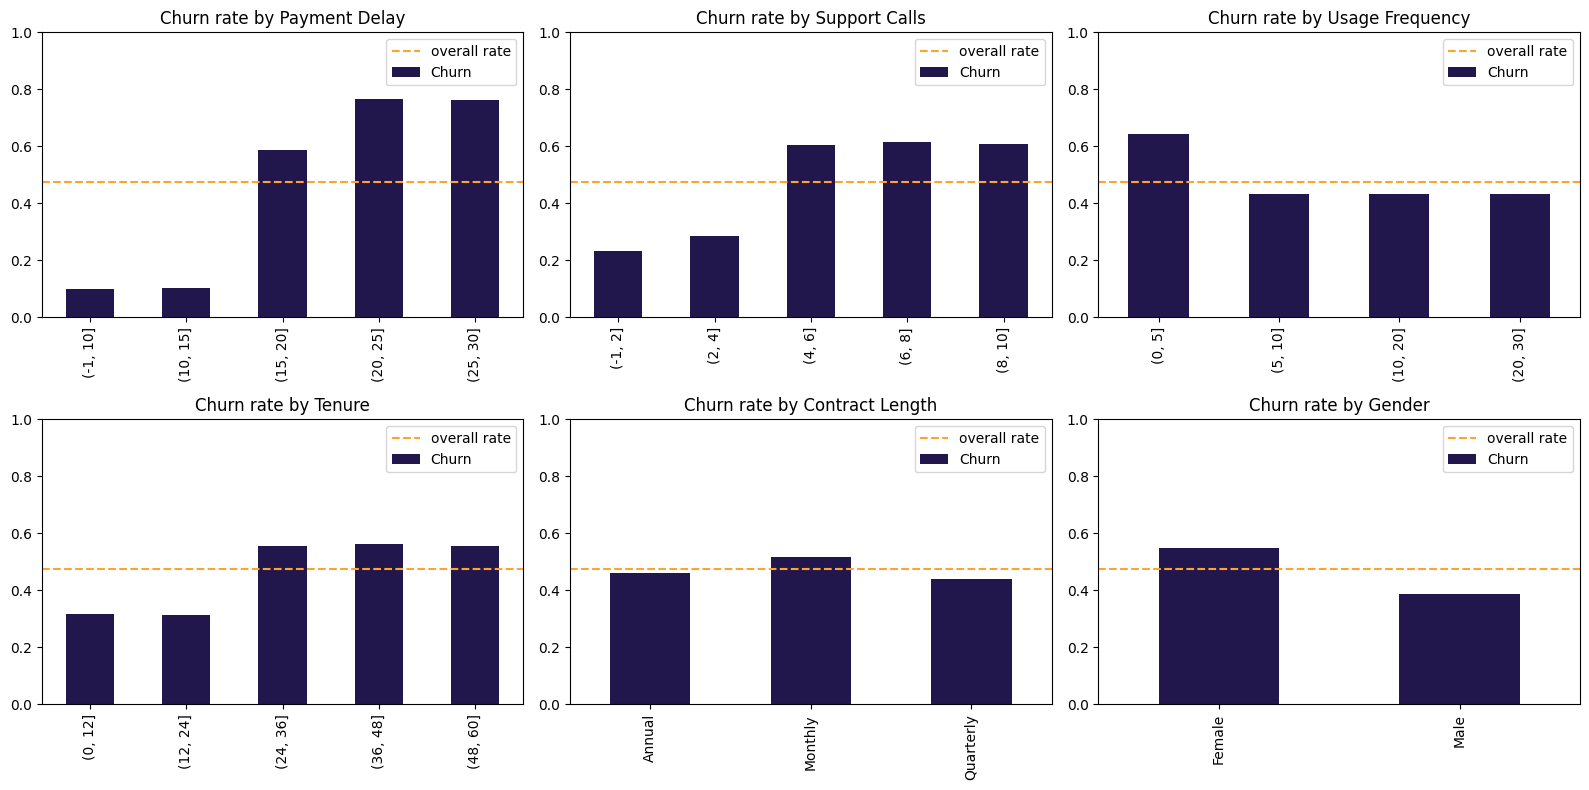

In [3]:
def churn_rate_by(col, bins=None):
    key = pd.cut(df[col], bins=bins) if bins is not None else df[col]
    return df.groupby(key, observed=True)["Churn"].mean().round(3)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
specs = [("Payment Delay", [-1, 10, 15, 20, 25, 30]), ("Support Calls", [-1, 2, 4, 6, 8, 10]),
         ("Usage Frequency", [0, 5, 10, 20, 30]), ("Tenure", [0, 12, 24, 36, 48, 60]),
         ("Contract Length", None), ("Gender", None)]
for ax, (col, bins) in zip(axes.flat, specs):
    churn_rate_by(col, bins).plot(kind="bar", ax=ax, color="#22174D")
    ax.axhline(df["Churn"].mean(), color="#FEA330", linestyle="--", label="overall rate")
    ax.set_title(f"Churn rate by {col}"); ax.set_ylim(0, 1); ax.set_xlabel(""); ax.legend()
plt.tight_layout(); plt.show()

In [4]:
signals = pd.DataFrame({
    "Customers": [len(df), (df["Payment Delay"] > 20).sum(), (df["Support Calls"] >= 5).sum(), (df["Usage Frequency"] <= 5).sum()],
    "Churn rate": [df["Churn"].mean(), df.loc[df["Payment Delay"] > 20, "Churn"].mean(),
                   df.loc[df["Support Calls"] >= 5, "Churn"].mean(), df.loc[df["Usage Frequency"] <= 5, "Churn"].mean()],
}, index=["All customers", "Payment delay > 20 days", "5+ support calls", "Used the service 5 times or fewer"]).round(3)
signals

,Customers,Churn rate
All customers,64374,0.474
Payment delay > 20 days,27679,0.766
5+ support calls,39795,0.609
Used the service 5 times or fewer,12500,0.645


**Observations**
- **Late payment is the strongest signal:** about 77% of customers more than 20 days late churn, versus about 10% of those no more than 10 days late.
- **Support calls show a step:** churn sits around 23-25% for up to 3 calls, then jumps to about 60% from 5 calls upward, a natural trigger for a retention call.
- **Low usage** and **monthly contracts** also raise churn. Spend, plan type and days since last interaction barely matter.

## 3. Models (5-fold cross-validation on 80% of the data)

In [5]:
X = df.drop(columns=["CustomerID", "Churn"])
y = df["Churn"]
numeric = ["Age", "Tenure", "Usage Frequency", "Support Calls", "Payment Delay", "Total Spend", "Last Interaction"]
categorical = ["Gender", "Subscription Type", "Contract Length"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
preprocess = ColumnTransformer([("num", StandardScaler(), numeric),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), categorical)])
models = {
    "Majority class (baseline)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Random forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.1, eval_metric="logloss",
                             n_jobs=-1, random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    s = cross_validate(Pipeline([("prep", preprocess), ("model", model)]), X_train, y_train, cv=cv,
                       scoring=["accuracy", "recall", "precision", "roc_auc"])
    rows.append({"Model": name, "Accuracy": s["test_accuracy"].mean(), "Recall": s["test_recall"].mean(),
                 "Precision": s["test_precision"].mean(), "ROC-AUC": s["test_roc_auc"].mean()})
pd.DataFrame(rows).set_index("Model").round(3)

,Accuracy,Recall,Precision,ROC-AUC
Model,,,,
Majority class (baseline),0.526,0.000,0.000,0.500
Logistic regression,0.826,0.828,0.809,0.904
Random forest,0.997,0.995,0.999,1.000
XGBoost,1.000,1.000,1.000,1.000


**Reading the comparison:** logistic regression reaches about 83% accuracy, while the tree models are close to 100%. The gap means churn here depends on **combinations** of factors (for example, many support calls *and* long tenure) that a straight-line model cannot capture but trees can.

A near-perfect score on held-out data is unusual for real churn, so before trusting it, Section 5 checks why.

## 4. Held-out test set

XGBoost errors on the test set: 0 out of 12875
                     Accuracy  Recall  ROC-AUC
Logistic regression     0.827  0.8234    0.903
XGBoost                 1.000  1.0000    1.000


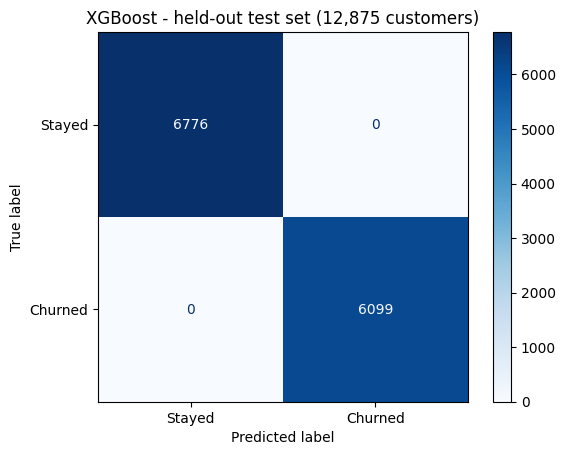

In [6]:
final = Pipeline([("prep", preprocess), ("model", models["XGBoost"])]).fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
lr = Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=1000))]).fit(X_train, y_train)
lr_proba = lr.predict_proba(X_test)[:, 1]

print("XGBoost errors on the test set:", int((pred != y_test).sum()), "out of", len(y_test))
print(pd.DataFrame({
    "Accuracy": [accuracy_score(y_test, (lr_proba >= 0.5).astype(int)), accuracy_score(y_test, pred)],
    "Recall": [recall_score(y_test, (lr_proba >= 0.5).astype(int)), recall_score(y_test, pred)],
    "ROC-AUC": [roc_auc_score(y_test, lr_proba), roc_auc_score(y_test, proba)],
}, index=["Logistic regression", "XGBoost"]).round(4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Stayed", "Churned"]).plot(cmap="Blues")
plt.title(f"XGBoost - held-out test set ({len(y_test):,} customers)"); plt.show()

## 5. Sanity check: is a ~100% score believable?
If churn were driven by messy human behaviour, even the best model would make many mistakes. One way to test this is to see how small a decision tree can be and still predict churn almost perfectly. If a small set of yes/no thresholds explains nearly everything, the labels were probably **generated by rules**, which is typical of synthetic practice datasets.

            Leaves  Test accuracy
Tree depth                       
1                2         0.7850
2                4         0.8207
3                7         0.8917
4               12         0.9425
6               36         0.9799
8               70         0.9964
10              97         0.9984


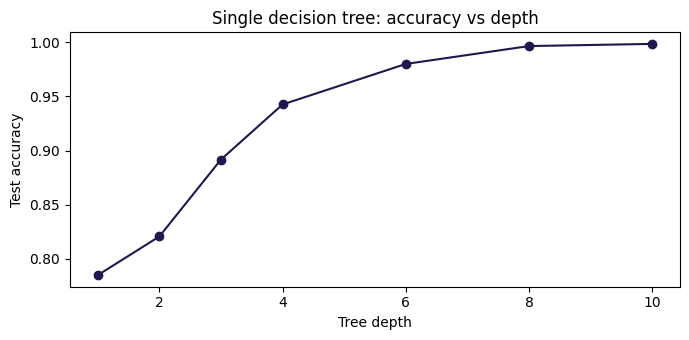

In [7]:
depth_rows = []
for d in [1, 2, 3, 4, 6, 8, 10]:
    tree = Pipeline([("prep", preprocess), ("model", DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))])
    tree.fit(X_train, y_train)
    depth_rows.append({"Tree depth": d, "Leaves": tree.named_steps["model"].get_n_leaves(),
                       "Test accuracy": accuracy_score(y_test, tree.predict(X_test))})
depth = pd.DataFrame(depth_rows).set_index("Tree depth").round(4)
print(depth)
depth["Test accuracy"].plot(marker="o", color="#22174D", figsize=(7, 3.5), title="Single decision tree: accuracy vs depth")
plt.ylabel("Test accuracy"); plt.tight_layout(); plt.show()

**Result:** a single tree with about 10 levels of yes/no rules predicts churn almost perfectly, and accuracy climbs steadily as rules are added, with sharp thresholds such as *payment delay > 20 days* and *5+ support calls*. Real customers do not behave this cleanly, so this dataset is very likely synthetic, with churn generated from threshold rules.

**What that means:** the model is good at recovering the rules, but the ~100% figure would **not** carry over to a real customer base. On real data I would expect noticeably lower accuracy and would report it against the logistic-regression and majority baselines.

## 6. What drives churn

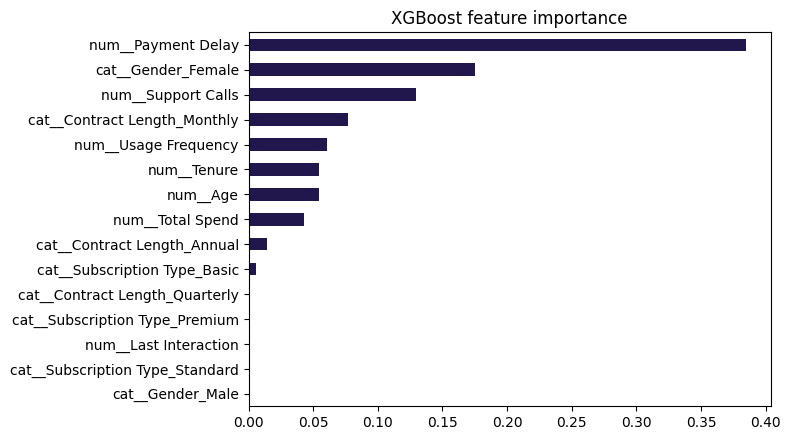

In [8]:
names = final.named_steps["prep"].get_feature_names_out()
imp = pd.Series(final.named_steps["model"].feature_importances_, index=names).sort_values()
imp.plot(kind="barh", figsize=(8, 4.5), color="#22174D")
plt.title("XGBoost feature importance"); plt.tight_layout(); plt.show()

## 7. Conclusions and recommendations
- **Retention triggers a team could use today:** flag customers who are more than 20 days late on payment, who have made 5 or more support calls, or whose usage drops to 5 or fewer sessions, and contact them before renewal. Moving monthly customers to quarterly or annual contracts is also associated with lower churn.
- **Model choice:** tree-based models capture the interactions between these signals far better than a linear model (about 100% vs 83% accuracy).
- **Honest caveat:** the near-perfect score comes from rule-like, likely synthetic labels. Before using this approach on real data I would expect lower accuracy, tune the decision threshold to the cost of a retention offer versus a lost customer, and review whether gender should be used at all, since targeting by gender raises fairness concerns.